In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## dapo-fig2

**Figure 2: AIME accuracy (avg@32) over training with and without Clip-Higher.** Dashed lines mark each run's best accuracy. With Clip-Higher, accuracy peaks at 0.406, against 0.269 without it.

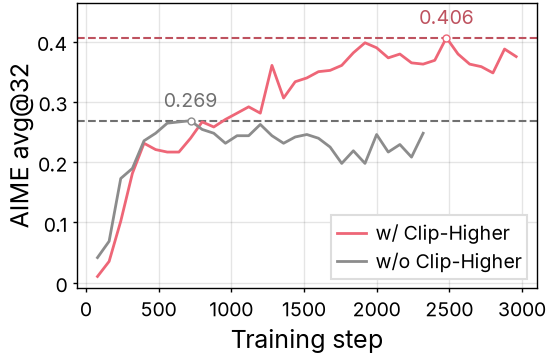

In [2]:
data = json.load(open("../data/dapo.json"))["fig2a"]
ours = data["w/ Clip-Higher"]
base = data["w/o Clip-Higher"]

fig, ax = plt.subplots(figsize=(2.75, 2))
ax.plot(ours["step"], ours["value"], color=colors["ours"], label="w/ Clip-Higher")
ax.plot(base["step"], base["value"], color=colors["neutral"], label="w/o Clip-Higher")

for run, color in [(ours, colors["ours"]), (base, colors["neutral"])]:
    best = int(np.argmax(run["value"]))
    mark_value(ax, run["step"][best], run["value"][best], f"{run['value'][best]:#.3g}", color)

ax.set_xlabel("Training step")
ax.set_ylabel("AIME avg@32")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/dapo-fig2.pdf")
fig.savefig("../outputs/dapo-fig2.png")
plt.show()

## dapo-fig6

**Figure 6: AIME accuracy (avg@32) over training of a baseline setting before and after applying dynamic sampling.** Dashed lines mark each run's best accuracy. With dynamic sampling, accuracy reaches the baseline's best of 0.421 at step 2,160 instead of 6,080, 2.8× fewer steps, and peaks at 0.438.

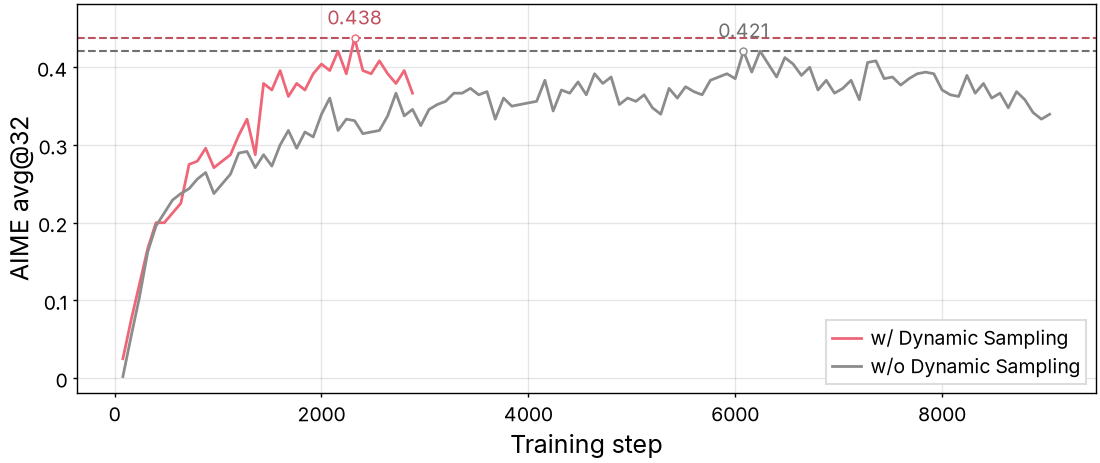

In [3]:
data = json.load(open("../data/dapo.json"))["fig6"]
ours = data["w/ Dynamic Sampling"]
base = data["w/o Dynamic Sampling"]

fig, ax = plt.subplots(figsize=(5.5, 2))
ax.plot(ours["step"], ours["value"], color=colors["ours"], label="w/ Dynamic Sampling")
ax.plot(base["step"], base["value"], color=colors["neutral"], label="w/o Dynamic Sampling")

for run, color in [(ours, colors["ours"]), (base, colors["neutral"])]:
    best = int(np.argmax(run["value"]))
    mark_value(ax, run["step"][best], run["value"][best], f"{run['value'][best]:#.3g}", color)

ax.set_xlabel("Training step")
ax.set_ylabel("AIME avg@32")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=0.382)
fig.savefig("../outputs/dapo-fig6.pdf")
fig.savefig("../outputs/dapo-fig6.png")
plt.show()

## rlvr-fig2

**Figure 2: Pass@k of base models and their RLVR-trained counterparts (SimpleRL-Zoo, GRPO) across four mathematical benchmarks.** Rows are benchmarks and columns are models; the x axis is log₂-scaled. In all 16 panels the RL-trained model leads at k = 1 but the base model overtakes it at large k: on AIME24 with Qwen2.5-7B, RL leads 0.154 to 0.074 at k = 1, while the base model reaches 0.767 against 0.633 at k = 1024.

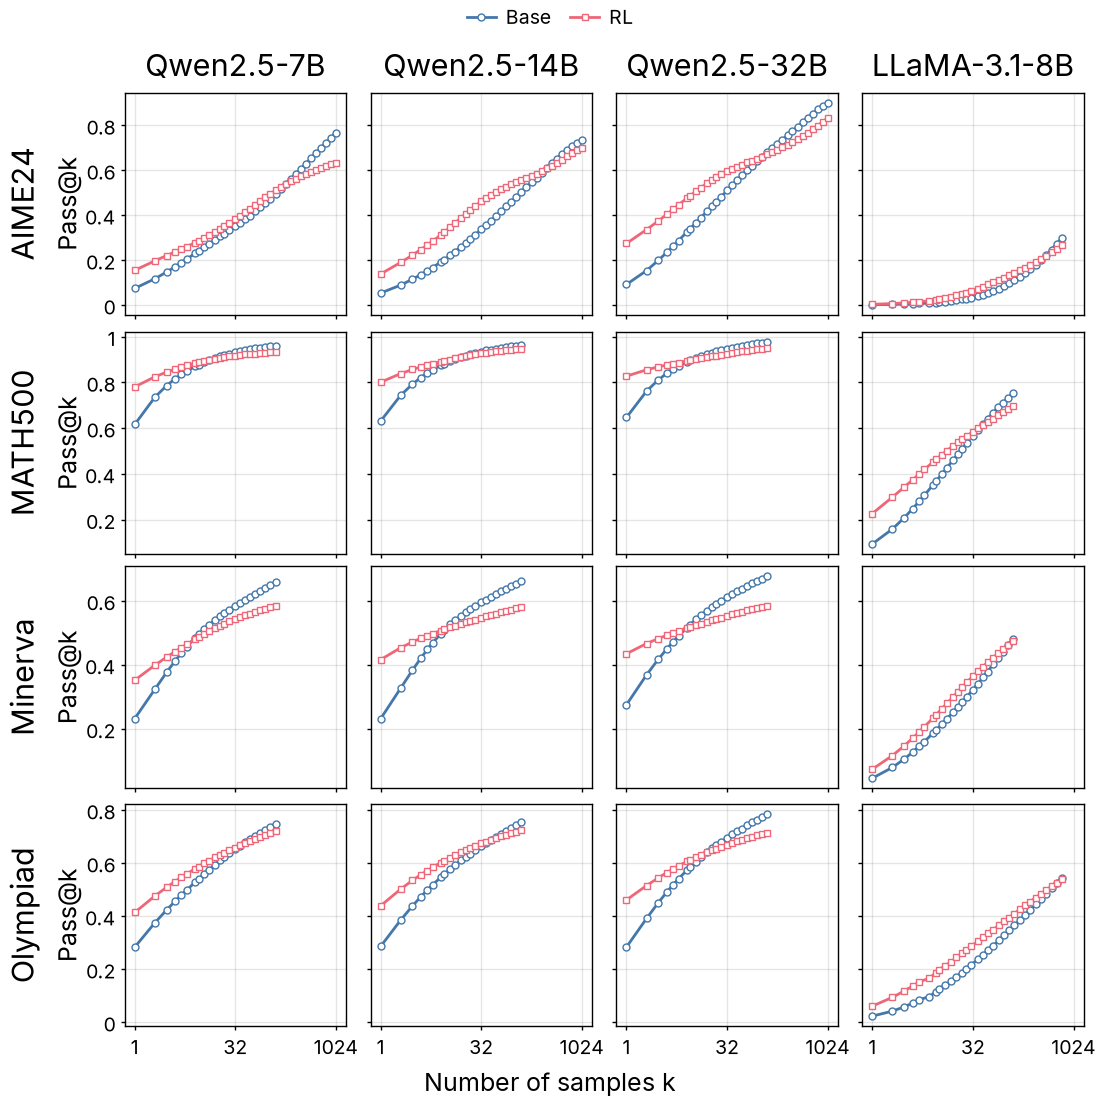

In [4]:
data = json.load(open("../data/rlvr.json"))
benchmarks = ["AIME24", "MATH500", "Minerva", "Olympiad"]
models = ["Qwen2.5-7B", "Qwen2.5-14B", "Qwen2.5-32B", "LLaMA-3.1-8B"]

fig, axes = plt.subplots(4, 4, figsize=(5.5, 5.5), sharex="col", sharey="row")
for r, benchmark in enumerate(benchmarks):
    for c, model in enumerate(models):
        ax = axes[r, c]
        curves = data[benchmark][model]
        ax.plot(curves["Base"]["k"], curves["Base"]["pass"], "o-", color=colors["series-1"], label="Base")
        ax.plot(curves["RL"]["k"], curves["RL"]["pass"], "s-", color=colors["series-2"], label="RL")
        ax.set_xscale("log", base=2)

top = 1024
ks = [1, 32, 1024]
for c, model in enumerate(models):
    margin = 2 ** (0.05 * math.log2(top))
    axes[-1, c].set_xticks(ks, labels=[str(k) for k in ks])
    axes[-1, c].set_xticks([], minor=True)
    axes[-1, c].set_xlim(1 / margin, top * margin)
    axes[0, c].set_title(model)

for r, benchmark in enumerate(benchmarks):
    axes[r, 0].yaxis.set_major_formatter(lambda v, _: f"{v:g}")
    axes[r, 0].set_ylabel("Pass@k")
    axes[r, 0].annotate(benchmark, xy=(0, 0.5), xycoords=axes[r, 0].yaxis.label, xytext=(-4, 0),
                        textcoords="offset points", ha="right", va="center", rotation=90, fontsize=11)

fig.supxlabel("Number of samples k")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, borderaxespad=0)

fit_height(fig, axes, aspect=1.0, min_width=1.0)
fig.savefig("../outputs/rlvr-fig2.pdf")
fig.savefig("../outputs/rlvr-fig2.png")
plt.show()

## rlvr-fig5

**Figure 5: Per-problem accuracy of Qwen2.5-7B on Minerva (272 problems), base model versus its RLVR-trained version (SimpleRL-Zoo).** Bars count the problems whose accuracy falls in each interval; 0.0 and 1.0 are exact values. RLVR raises the number of problems solved every time from 3 to 47 and cuts the low intervals (0.1–0.2: 17 to 12), but also raises the number never solved from 93 to 113.

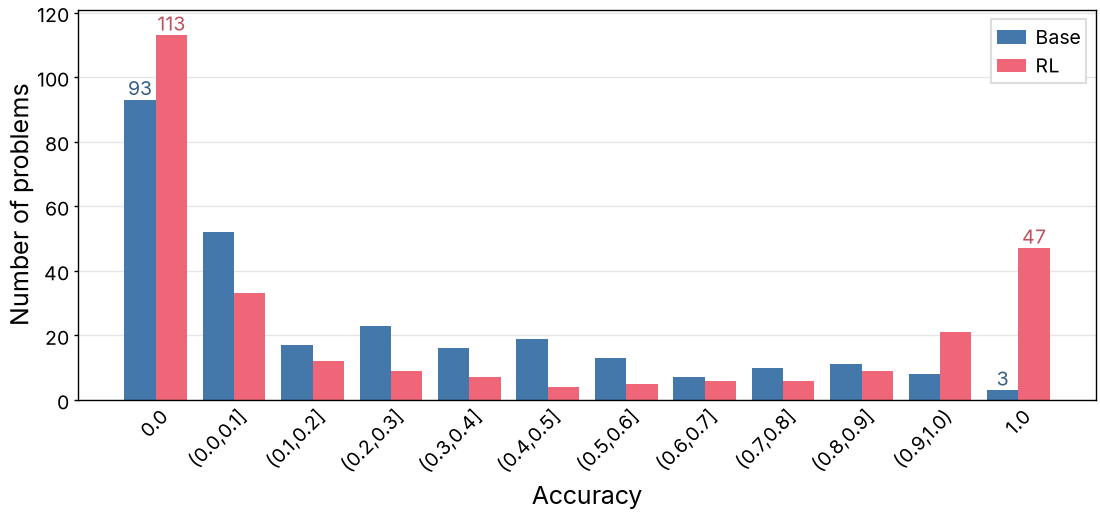

In [5]:
data = json.load(open("../data/rlvr-fig5.json"))
bins = data["bins"]
x = np.arange(len(bins))
width = 0.8 / 2

fig, ax = plt.subplots(figsize=(5.5, 2))
for i, (name, color) in enumerate([("Base", colors["series-1"]), ("RL", colors["series-2"])]):
    bars = ax.bar(x + (i - 0.5) * width, data[name], width, color=color, linewidth=0, label=name)
    compared = [0, len(bins) - 1]
    ax.bar_label(bars, labels=[str(v) if j in compared else "" for j, v in enumerate(data[name])],
                 color=darken(color))

ax.set_xticks(x, labels=bins, rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Accuracy")
ax.set_ylabel("Number of problems")
ax.legend(loc="upper right")

fit_height(fig, ax, aspect=0.382)
fig.savefig("../outputs/rlvr-fig5.pdf")
fig.savefig("../outputs/rlvr-fig5.png")
plt.show()

## rlvr-fig6

**Figure 6: Perplexity of individual responses to one AIME24 problem, under Qwen2.5-7B-Base and its RLVR-trained version.** PPL_M(Y_S) is model M's perplexity on responses sampled from S (GT: responses from OpenAI-o1); boxes span the quartiles with the median as a line, whiskers reach 1.5× the interquartile range, and each point is one response (16 per group; 7 for GT, as one point of the original could not be recovered). The base model's perplexity on the RL model's responses (median 1.056, at most 1.088) matches the lower part of its perplexity on its own responses (median 1.084, up to 1.126): the RL model's responses are ones the base model already tends to generate.

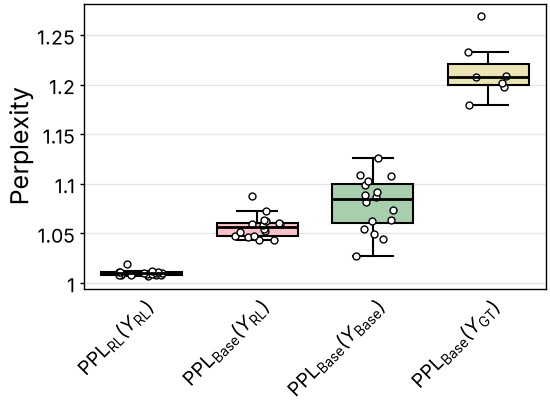

In [6]:
data = json.load(open("../data/rlvr-fig6.json"))["Problem 1"]
groups = [
    ("PPL_RL(Y_RL)", r"$\mathrm{PPL}_{\mathrm{RL}}(Y_{\mathrm{RL}})$", colors["series-1"]),
    ("PPL_Base(Y_RL)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{RL}})$", colors["series-2"]),
    ("PPL_Base(Y_Base)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{Base}})$", colors["series-3"]),
    ("PPL_Base(Y_GT)", r"$\mathrm{PPL}_{\mathrm{Base}}(Y_{\mathrm{GT}})$", colors["series-4"]),
]
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(2.75, 2))
for x, (key, label, color) in enumerate(groups):
    values = data[key]
    box = ax.boxplot(values, positions=[x], widths=0.7, showfliers=False)
    box["boxes"][0].set_facecolor(lighten(color))
    ax.plot(x + rng.uniform(-0.2, 0.2, len(values)), values, "o", color="black", markerfacecolor="white", linestyle="none")

ax.set_xticks(range(len(groups)), labels=[label for _, label, _ in groups], rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Perplexity")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/rlvr-fig6.pdf")
fig.savefig("../outputs/rlvr-fig6.png")
plt.show()